![trimming](../images/trimming.png)

- As we start storing previous messages, the storing stack gets bigger and bigger, ends up increasing input token counts. And if the token count goes beyond the context window, LLM silently drops the extra information. This is call context overflow problem

- To solve this issue there are multiple approaches 

### 1.Trimming

When we see token count of the input is beyond the maximum token for the LLM, then we retain latest information allowed by the token limit and rest is dropped. 

In [13]:
from langgraph.graph import StateGraph, START, MessagesState
from langgraph.checkpoint.memory import InMemorySaver
from dotenv import load_dotenv

from langchain_openai import ChatOpenAI
from langchain_core.messages.utils import trim_messages, count_tokens_approximately

In [14]:
load_dotenv()

True

In [15]:
model = ChatOpenAI(model = "gpt-4o")

In [16]:
MAX_TOKEN = 100

In [17]:
def call_model(state:MessagesState):
    messages = trim_messages(
        state["messages"],
        strategy = "last",
        token_counter = count_tokens_approximately,
        max_tokens = MAX_TOKEN
    )
    print("current token count ->", count_tokens_approximately(messages=messages))

    for message in messages:
        print(message.content)

    response = model.invoke(messages)   # pass the whole trimmed list, once

    return {"messages":[response]}

In [18]:
builder = StateGraph(MessagesState)
builder.add_node("call_model", call_model)
builder.add_edge(START, "call_model")



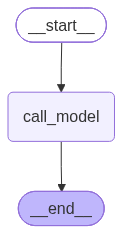

In [19]:
checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)
graph

In [20]:
config = {"configurable":{"thread_id": "chat-1"}}
result = graph.invoke(
    {"messages":[{"role":"user","content":"Hi, I am Bani"}]},config=config
)
result["messages"][-1].content

current token count -> 8
Hi, I am Bani


'Hello, Bani! How can I assist you today?'

In [21]:
result = graph.invoke(
    {"messages":[{"role":"user","content":"I am learning LangGraph"}]},config=config
)
result["messages"][-1].content

current token count -> 34
Hi, I am Bani
Hello, Bani! How can I assist you today?
I am learning LangGraph


'That sounds interesting! LangGraph is a library designed to work with natural language processing (NLP) applications, often used to build language models and other related utilities. If you have any specific questions or need help with certain concepts in LangGraph, feel free to ask.'

In [22]:
result = graph.invoke(
    {"messages":[{"role":"user","content":"What is machine learning?"}]},config=config
)
result["messages"][-1].content

current token count -> 98
I am learning LangGraph
That sounds interesting! LangGraph is a library designed to work with natural language processing (NLP) applications, often used to build language models and other related utilities. If you have any specific questions or need help with certain concepts in LangGraph, feel free to ask.
What is machine learning?


"Machine learning is a subset of artificial intelligence (AI) that involves the development of algorithms and statistical models that enable computers to perform tasks without explicit instructions. Instead of being programmed with specific rules, machine learning systems learn patterns and make decisions from data. Here's a broad overview of the main concepts:\n\n1. **Types of Machine Learning:**\n   - **Supervised Learning:** The algorithm is trained on a labeled dataset, which means that each training example is paired with an output label. Tasks like classification and regression use supervised learning.\n   - **Unsupervised Learning:** The algorithm explores the data without explicit instructions on what to learn and finds hidden patterns or intrinsic structures in the input data. Clustering and dimensionality reduction are common tasks.\n   - **Semi-supervised Learning:** A combination of supervised and unsupervised learning methods, where the model is trained on a small amount o

In [23]:
result = graph.invoke(
    {"messages":[{"role":"user","content":"What ismy name?"}]},config=config
)
result["messages"][-1].content

current token count -> 8
What ismy name?


"I'm sorry, but I don't have access to personal data about you, so I don't know your name. If you'd like, you can share it or ask me anything else!"